# Abstract

The following project performs explanitory data analysis on an income inequality dataset used in reserach by Thomas Frank, in an attempt to ground claims about income inequality in the United States with hard data.  We find that nationally, income inequality has increased and decreased with events over time, with a steady increase shown starting from 1980 and continuing on into the present day.  When broken down by state, there are differences in income inequality that can be seen, however, we find that state measures tend to change in the same way as the national average. 

# Introduction

Income inequality is a pervasive problem in the United States of America, and a hotly debated topic in American politics.  Common perception is that income inequality has increased in modern times, and this inequality can be connected to other societal issues such as drug use, the housing crisis, views on immigration, and the general change in the zeitgeist that comes with a lack of social mobility.  However, given the vast array of disinformation in the world of politically contentious topics, it would be nice to ground these claims in a data-centered analysis.  

In this analysis, I hope to learn more about how income inequality has changed over time.  While I have not settled on specific research questions, I would first like to measure how income inequality has changed over time nationally, in order to back my assumptions in a grounded method.  Nextly, I would like to use the breakdown by state to ask a couple of questions about how income inequality differs between states.  I would like to know which states have the highest disparity when it comes to income, and which have the least.  In addition, I am interested to know which states have made measurable gains when it comes to income inequality, and where the problem has gotten worse in the United States.  Lastly, if I have time, I would like to see if I can find patterns that match how each state votes in elections to see if certain states see more change when a particular party is in office, or if states see improvements in income inequality when the candidate that they voted for has power.



# Background or Related Work

https://eml.berkeley.edu/~saez/SaezZucman14slides.pdf
This both confirms and denies the original hypothesis about national income inequality over time.  It shows that, when measured by the wealth share of the top 0.1%, income inequality shrank after the great depression, and the increase in income inequality starting in the 1980s brought that measure back to the level it was at during the Roaring Twenties.
While this confirms my original hypothesis, I would still be curious as to if the hypothesis holds up with the other measures of income inequality measured in this dataset, as well as after segmenting by state.

https://www.sciencedirect.com/science/article/abs/pii/S1570677X26000304?via=ihub#recommended-articles
This was the article published by Mark W. Frank, who curated the dataset I used.  He used the income inequality dataset to ask whether suicide rates were linked to high measures of income inequality.  He found that while a high top 1% income threshold shows a strong correlation in rural areas, firearm access and a lack of health insurance remain stronger indicators of suicide rate than gini index on a county level in the United States. 
I was only able to access the article preview and section snippets without running into a paywall, so I wasn’t able to find any EDA on Frank’s dataset.  However, the results of his analysis indicate that it might be worth my time to also do some EDA on 1% income thresholds as well.


# Research questions or hypotheses


## Research question:
Which states are doing the best and worst in terms of income inequality?
### Hypothesis:
I think states with a highly educated population (i.e. New England) and smaller states are doing better than larger and less educated states. 


## Research question: 
Which states have income inequality that has grown or shrank over time more or less?
### Hypothesis:
Income inequality has changed fairly constantly across all states.

TODO: remove this
## Research question:
Which measure of income inequality shows the most change over time?  Do any measures tell a different story than the rest?
### Hypothesis:
The general patterns around income inequality remain constant amongst all four different ways of measuring income inequality. 

## Research question:
How has income inequality changed over time?
### Hypothesis:
Income inequality, by all measures, was about constant between 1913 to the 1980s, and has been increasing ever since.

# Discussion (including Limitations and Implications)


# Methodology:


### Data Gathering and Processing:
The data is currently downloaded as four CSV’s.
First, we will upload the “income inequality measures by state” csv into DataFrames using Pandas.
Then, we will horizontally transform this dataframe in order to allow us to graph equality over time.  Each row will represent a state (or “national”), and each column will represent a year.  There will be four such dataframes, one for each measure of inequality. 


Research question: Which states are doing the best and worst in terms of income inequality?
Methodology:  I will use only data from the most recent year to answer this question.  I will conduct this analysis for all four measures of income inequality, but only present one of them for my final presentation, or an aggregation of the four, if I deem that the most fair and appropriate way to do this.  I will create a visualization to present this as a choloropleth map using plotly (https://plotly.com/python/choropleth-maps/).
Why this is useful: A chloropleth map will allow us to get a quick visualization of all 50 states, and allow us to visually identify patterns in the data based on the location of the states on a map and previous knowledge of America..



Research question: Which states have income inequality that has grown or shrunk over time more or less?

Methodology: 
First, I will measure the change in inequality based on the difference in income inequality between an inflection point in the national graph (where I expect there to be one in the 1980’s) and the most recent data.  I will create a dataframe for all 50 states and analyze this by myself.
Then, I will make a graph measuring national income inequality over time.  On the x axis will be the year, and on the y axis will be the measure of inequality, with more inequality on top.  I will choose one measure that I find most representative of the data, or use an aggregate if the measures vary significantly.  There will be a couple of different lines, one for each state I find significant to present, based on patterns in the data.  As a graph including all 50 states would be too cluttered to analyze visually,  I will hand pick different states that best highlight unique interesting patterns in the data, while keeping the graph visually digestible. 
Why this is useful: 
It will be interesting to see whether the national pattern around income inequality is reflected equally across states, or whether certain states were affected by the national change differently than others.  Getting state by state data might provide us further insight as to the exact impacts of these national changes.

Import the necessary libraries

In [11]:
import pandas as pd
from matplotlib import pyplot as plt
import plotly.express as px

LATEST_YEAR = 2023

Upload the data from the excel spreadsheet provided from [Frank's website](https://profiles.shsu.edu/eco_mwf/inequality.html).

In [12]:
df = pd.read_excel("Frank_StateGini_2023.xlsx", sheet_name="Measures")
display(df.head())

,Year,st,State,TaxReturn,AGI,Atkin05,Gini,Gini_Positive,RMeanDev,RMeanDev_Positive,Theil
0,1916,0,United States,429401.0,6298577.620,0.331293,0.602385,0.602385,0.94117,0.94117,1.084234
1,1916,1,Alabama,2085.0,18469.010,0.144212,0.41161,0.41161,0.615382,0.615382,0.35638
2,1916,3,Arizona,989.0,11777.241,0.225292,0.511797,0.511797,0.781272,0.781272,0.601138
3,1916,4,Arkansas,2241.0,17683.678,0.119538,0.372056,0.372056,0.553058,0.553058,0.293588
4,1916,5,California,20865.0,228324.945,0.23524,0.512487,0.512487,0.78378,0.78378,0.665951


In the data provided in the website, each row represents a state-year.

This horizontal pivot makes each row a state, and each column represents the year in which Gini Index was measured.
This is necessary to create a graph over time. 
To compare other measures of inequality, we can do the same pivot on a different value to get the corresponding table.

In [13]:
gini_indexes = df.pivot(
    index="State",
    columns="Year",
    values="Gini"
)

gini_indexes = gini_indexes.apply(pd.to_numeric, errors="coerce")
gini_indexes.tail()

Year,1916,1917,1918,1919,1920,1921,1922,1923,1924,1925,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
State,,,,,,,,,,,,,,,,,,,,,
Virginia,0.479211,0.435853,0.384198,0.389563,0.359290,0.362613,0.384145,0.363354,0.395939,0.436693,...,0.596634,0.596599,0.594178,0.598349,0.597394,0.601417,0.618273,0.627665,0.604493,0.589983
Washington,0.477874,0.397824,0.336608,0.388325,0.318386,0.389955,0.338342,0.326043,0.333878,0.381398,...,0.611318,0.606858,0.609310,0.607456,0.604622,0.612536,0.633454,0.643175,0.603223,0.587957
West Virginia,0.516399,0.482665,0.353017,0.392064,0.337501,0.359124,0.394459,0.364707,0.383728,0.431410,...,0.552747,0.548023,0.545276,0.548593,0.545044,0.547939,0.570184,0.565188,0.553120,0.539659
Wisconsin,0.517161,0.441685,0.391591,0.393088,0.389081,0.413426,0.412250,0.378074,0.405878,0.447488,...,0.580786,0.582054,0.580280,0.577869,0.577300,0.578245,0.595997,0.593578,0.573193,0.560419
Wyoming,0.441190,0.428996,0.428132,0.341818,0.242975,0.311018,0.339329,0.309807,0.324435,0.374101,...,0.657783,0.658986,0.671621,0.678396,0.657866,0.674974,0.731162,0.730728,0.688086,0.663834


I will make a graph measuring national income inequality over time.
On the x axis will be the year, and on the y axis will be a scale for gini index, with a greater value representing more inequality.

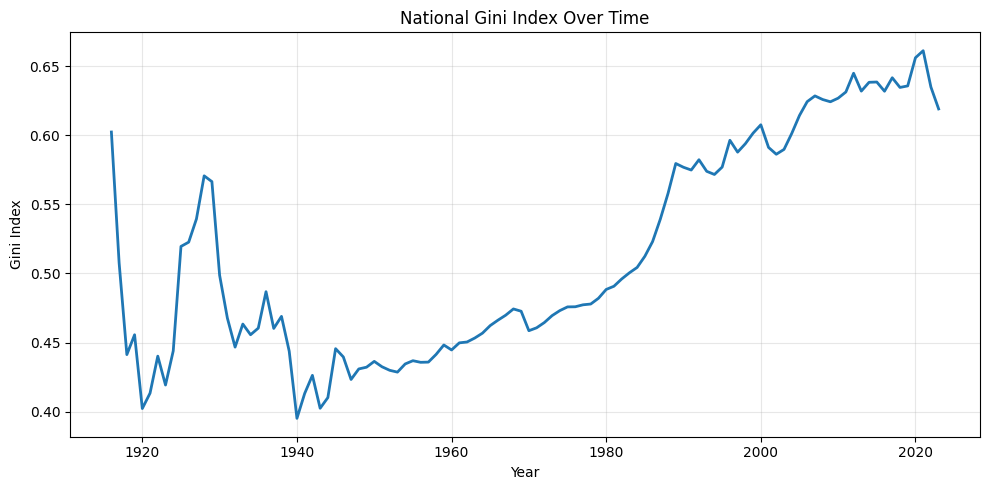

In [14]:
national = gini_indexes.loc["United States"]

plt.figure(figsize=(10, 5))
plt.plot(national.index, national.values, linewidth=2)

plt.title("National Gini Index Over Time")
plt.xlabel("Year")
plt.ylabel("Gini Index")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The following code maps state names as it appears in Frank's dataset to the state codes
in plotly's choloropleth map, so that we can create a chloropleth of all 50 states.

In [15]:
state_names = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "District of Columbia", "Florida", "Georgia",
    "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky",
    "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
    "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada",
    "New Hampshire", "New Jersey", "New Mexico", "New York",
    "North Carolina", "North Dakota", "Ohio", "Oklahoma", "Oregon",
    "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota",
    "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington",
    "West Virginia", "Wisconsin", "Wyoming"
]
state_codes = [
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "DC", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD", "MA",
    "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ", "NM", "NY",
    "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC", "SD", "TN", "TX",
    "UT", "VT", "VA", "WA", "WV", "WI", "WY"
]
state_abbrev = dict(zip(state_names, state_codes))

We are going to create multiple choropleths in this analysis, and a lot of the code
needed to create a choropleth is similar, so I create this function that allows us to 
input the transformed dataframe for a given metric and a column of choosing and
create a chloropleth to map this column on all 50 states. 

In [16]:
def create_chloropleth(df, year, color= px.colors.sequential.YlOrRd, metric=None, title=None ):
    if not title:
        if not metric:
            title = f"State Gini Indicies ({year})"
        else:
            title = f"State {metric} ({year})"

    latest = (
        df[year]
        .drop(index="United States")
        .rename("Gini")
        .rename_axis("State")
        .reset_index()
    )
    latest["StateCode"] = latest["State"].map(state_abbrev)

    return px.choropleth(
        latest,
        locations="StateCode",
        locationmode="USA-states",
        color="Gini",
        hover_name="State",
        scope="usa",
        title=title,
        color_continuous_scale=color
    )

Create the chloropleth for the latest year, which should be 2023.

In [17]:
create_chloropleth(gini_indexes, LATEST_YEAR).show()

Recreate the chloropleth for 1980

In [18]:
create_chloropleth(gini_indexes, 1980).show()

Redefine a new metric to represent the change between the two times, and create a chloropleth to explicitly show the change.

In [19]:
gini_indexes["delta_since_1980"] = gini_indexes[2023] - gini_indexes[1980]
create_chloropleth(gini_indexes, "delta_since_1980", px.colors.sequential.Reds).show()

Now, we will plot some states on a line graph to see how inequality has changed over time for different states.

I chose five states based on the results of the 1980 plot, the 2023 plot, and the difference plot, in hopes of finding states where gini indexes might change over time.  Admittedly, the choices are fairly arbitrary, so choosing other states might be a point of further work.

In [20]:
STATES_TO_PLOT = ["California", "Iowa", "West Virginia", "Washington", "South Dakota"]

df_plot = gini_indexes.loc[STATES_TO_PLOT]
df_plot.head()

Year,1916,1917,1918,1919,1920,1921,1922,1923,1924,1925,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,delta_since_1980
State,,,,,,,,,,,,,,,,,,,,,
California,0.512487,0.449363,0.417195,0.437414,0.391606,0.401281,0.411261,0.414620,0.424570,0.477047,...,0.675258,0.668459,0.671934,0.667601,0.665833,0.694641,0.692654,0.658810,0.643574,0.144407
Iowa,0.395946,0.300659,0.300824,0.320843,0.354971,0.322968,0.307837,0.334315,0.375397,0.434779,...,0.563984,0.560957,0.566139,0.562762,0.561196,0.584652,0.572751,0.561621,0.551592,0.068558
West Virginia,0.516399,0.482665,0.353017,0.392064,0.337501,0.359124,0.394459,0.364707,0.383728,0.431410,...,0.548023,0.545276,0.548593,0.545044,0.547939,0.570184,0.565188,0.553120,0.539659,0.087852
Washington,0.477874,0.397824,0.336608,0.388325,0.318386,0.389955,0.338342,0.326043,0.333878,0.381398,...,0.606858,0.609310,0.607456,0.604622,0.612536,0.633454,0.643175,0.603223,0.587957,0.115141
South Dakota,0.357501,0.240190,0.270469,0.303474,0.325063,0.352026,0.334993,0.319408,0.287989,0.312469,...,0.612092,0.615693,0.612233,0.617685,0.624211,0.648041,0.635891,0.611925,0.596628,0.047517


Graph to make the plot over time.

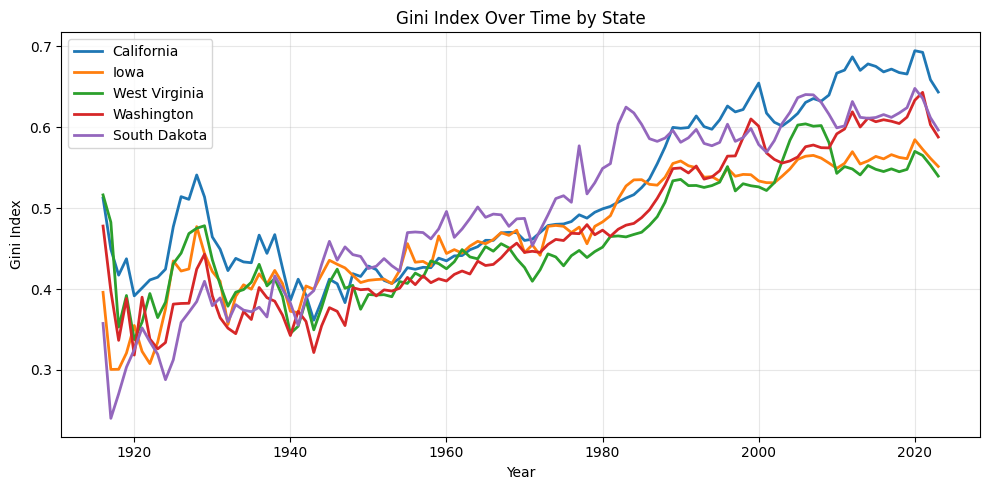

In [21]:
year_cols = sorted(
    [col for col in gini_indexes.columns if str(col).isdigit()],
    key=int
)

df_plot = gini_indexes.loc[STATES_TO_PLOT, year_cols].T

plt.figure(figsize=(10, 5))
for state in df_plot.columns:
    plt.plot(df_plot.index, df_plot[state], linewidth=2, label=state)

plt.title("Gini Index Over Time by State")
plt.xlabel("Year")
plt.ylabel("Gini Index")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Research question: Which measure of income inequality shows the most change over time?  Do any measures tell a different story than the rest?
Methodology: The first graph will provide the best visual analysis to answer this question, so I will not need to analyze this further than the steps I wrote out for the first three datasets.  Still, this might be something worth commenting on, either in the final presentation or in the codebase itself. 

# Conclusion

In conclusion, income inequality in the United States has changed over time.  It decreased during the Great Depression and stayed low past the Civil War and into the Cold War.  However, you can see that the Gini Index goes up nationally after the 1980's.  While we found this effect to be more paramount in larger states, income inequality as measured by the Gini Index has gone up for all states with fairly the same pattern as the national trend.
